# Taxi Hourly Demand Forecast

La compañía Sweet Lift Taxi ha recopilado datos históricos sobre pedidos de taxis en los aeropuertos. Para atraer a más conductores durante las horas pico, necesitamos predecir la cantidad de pedidos de taxis para la próxima hora. Construye un modelo para dicha predicción.

La métrica RECM en el conjunto de prueba no debe ser superior a 48.

## Instrucciones del proyecto.

1. Descarga los datos y haz el remuestreo por una hora.
2. Analiza los datos
3. Entrena diferentes modelos con diferentes hiperparámetros. La muestra de prueba debe ser el 10% del conjunto de datos inicial.4. Prueba los datos usando la muestra de prueba y proporciona una conclusión.

## Descripción de los datos

Los datos se almacenan en el archivo `taxi.csv`. 	
El número de pedidos está en la columna `num_orders`.


## Librerias y Arquitectura de Clases

### Estructura del Codigo

Se emplean dos clases reutilizables que encapsulan los procesos repetitivos del proyecto, siguiendo el principio DRY (*Don't Repeat Yourself*):

| Clase | Responsabilidad |
|---|---|
| `TimeSeriesExplorer` | Analisis exploratorio de datos (EDA): estadisticas, verificacion temporal y visualizaciones |
| `ModelTuner` | Entrenamiento, busqueda de hiperparametros y registro comparativo de modelos |

Ambas clases son independientes del dataset; pueden reutilizarse en cualquier proyecto de series temporales con un `DatetimeIndex`.

### Clase `TimeSeriesExplorer`

- **`__init__(df, target_col)`**: Almacena una copia del DataFrame y el nombre de la columna objetivo.
- **`reporte_estadistico()`**: Imprime informacion del schema, conteo de nulos, verificacion de orden cronologico (`is_monotonic_increasing`) y estadisticas descriptivas.
- **`reporte_visual()`**: Genera un histograma con KDE y un diagrama de caja para la columna objetivo.
- **`ejecutar_pipeline()`**: Ejecuta ambos reportes en secuencia y retorna el DataFrame para uso posterior.

### Clase `ModelTuner`

- **`__init__(X_train, y_train, cv)`**: Almacena los datos de entrenamiento y la estrategia de validacion cruzada.
- **`evaluar_modelo(nombre, modelo, param_grid)`**: Si `param_grid` contiene valores, ejecuta `GridSearchCV` para optimizar hiperparametros; en caso contrario, aplica `cross_val_score`. Registra RECM, tiempo de entrenamiento y tiempo de prediccion.
- **`mostrar_resumen()`**: Genera una tabla comparativa (leaderboard) ordenada por RECM ascendente y retorna el objeto del modelo ganador.


## Preparación


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
from statsmodels.tsa.seasonal import seasonal_decompose
from sklearn.model_selection import (
    train_test_split, TimeSeriesSplit, GridSearchCV, cross_val_score
)
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
import lightgbm as lgb
from sklearn.metrics import mean_squared_error

class TimeSeriesExplorer:
    """
    Pipeline de exploracion inicial para series temporales.

    Acepta cualquier DataFrame con DatetimeIndex y un nombre de columna objetivo.
    Genera un reporte estadistico y visualizaciones de distribucion sin modificar
    el DataFrame original.

    Parametros
    ----------
    df : pd.DataFrame
        DataFrame con DatetimeIndex.
    target_col : str
        Nombre de la columna numerica a analizar.
    """

    def __init__(self, df: pd.DataFrame, target_col: str):
        self.df = df.copy()
        self.target_col = target_col

    def reporte_estadistico(self) -> None:
        """Imprime schema, nulos, orden cronologico y estadisticas descriptivas."""
        print("--- INFORMACION GENERAL ---")
        self.df.info()

        print("\n--- VALORES NULOS ---")
        print(self.df.isna().sum())

        print("\n--- VERIFICACION DE ORDEN TEMPORAL ---")
        ordenado = self.df.index.is_monotonic_increasing
        print(f"Indice ordenado cronologicamente: {'SI' if ordenado else 'NO'}")

        print("\n--- ESTADISTICAS DESCRIPTIVAS ---")
        print(self.df.describe())

    def reporte_visual(self) -> None:
        """Genera histograma con KDE y diagrama de caja de la columna objetivo."""
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))
        fig.suptitle(f"Distribucion de '{self.target_col}' (datos crudos)", fontsize=13)

        sns.histplot(
            self.df[self.target_col], bins=50, kde=True,
            color='steelblue', ax=axes[0]
        )
        axes[0].set_title('Histograma con KDE')
        axes[0].set_xlabel('Valor')
        axes[0].set_ylabel('Frecuencia')

        sns.boxplot(x=self.df[self.target_col], color='steelblue', ax=axes[1])
        axes[1].set_title('Diagrama de Caja')
        axes[1].set_xlabel('Valor')

        plt.tight_layout()
        plt.show()

    def ejecutar_pipeline(self) -> pd.DataFrame:
        """Ejecuta reporte estadistico y visual. Retorna el DataFrame."""
        self.reporte_estadistico()
        self.reporte_visual()
        return self.df

class ModelTuner:
    """
    Pipeline de entrenamiento, busqueda de hiperparametros y comparacion de modelos.

    Compatible con cualquier estimador de scikit-learn. Registra internamente los
    resultados de cada modelo para generar un leaderboard comparativo.

    Parametros
    ----------
    X_train : pd.DataFrame
        Caracteristicas de entrenamiento.
    y_train : pd.Series
        Variable objetivo de entrenamiento.
    cv : objeto de validacion cruzada
        Estrategia de CV (e.g. TimeSeriesSplit) compatible con scikit-learn.
    """

    def __init__(self, X_train: pd.DataFrame, y_train: pd.Series, cv):
        self.X_train = X_train
        self.y_train = y_train
        self.cv = cv
        self._resultados = []

    def evaluar_modelo(self, nombre: str, modelo, param_grid: dict = None) -> None:
        """
        Evalua un modelo mediante validacion cruzada y registra los resultados.

        Si param_grid no es None, ejecuta GridSearchCV para encontrar los mejores
        hiperparametros. De lo contrario, evalua con cross_val_score el modelo
        tal como fue instanciado.

        Parametros
        ----------
        nombre : str
            Identificador del modelo en el leaderboard.
        modelo : estimador scikit-learn
            Instancia del modelo a evaluar.
        param_grid : dict, opcional
            Cuadricula de hiperparametros para GridSearchCV.
        """
        if param_grid:
            buscador = GridSearchCV(
                modelo, param_grid, cv=self.cv,
                scoring='neg_root_mean_squared_error', n_jobs=-1
            )
            t0 = time.time()
            buscador.fit(self.X_train, self.y_train)
            t_train = time.time() - t0

            mejor_modelo = buscador.best_estimator_
            mejor_recm   = -buscador.best_score_
            mejores_params = buscador.best_params_
        else:
            t0 = time.time()
            modelo.fit(self.X_train, self.y_train)
            t_train = time.time() - t0

            mejor_modelo = modelo
            scores = cross_val_score(
                modelo, self.X_train, self.y_train,
                cv=self.cv, scoring='neg_root_mean_squared_error', n_jobs=-1
            )
            mejor_recm    = -scores.mean()
            mejores_params = {}

        t0 = time.time()
        mejor_modelo.predict(self.X_train)
        t_pred = time.time() - t0

        self._resultados.append({
            'Modelo':          nombre,
            'RECM_CV':         round(mejor_recm, 4),
            'T_Train_s':       round(t_train, 3),
            'T_Pred_s':        round(t_pred, 4),
            'Parametros':      mejores_params,
            '_objeto':         mejor_modelo
        })

        print(
            f"[{nombre}]  RECM CV: {mejor_recm:.4f} | "
            f"T.Entrenamiento: {t_train:.3f}s | T.Prediccion: {t_pred:.4f}s"
        )

    def mostrar_resumen(self):
        """
        Imprime el leaderboard ordenado por RECM ascendente.
        Retorna el objeto del modelo con menor RECM.
        """
        df_res = (
            pd.DataFrame(self._resultados)
            .sort_values('RECM_CV')
            .reset_index(drop=True)
        )
        cols = ['Modelo', 'RECM_CV', 'T_Train_s', 'T_Pred_s', 'Parametros']
        print("\n--- LEADERBOARD ---")
        print(df_res[cols].to_string(index=False))

        ganador = df_res.iloc[0]
        print(f"\nModelo seleccionado: {ganador['Modelo']} | RECM CV: {ganador['RECM_CV']:.4f}")
        return ganador['_objeto']


## Carga, Inspeccion y Remuestreo

Los datos se cargan estableciendo la columna de tiempo como indice (`index_col=[0]`) y convirtiendola al tipo `datetime` (`parse_dates=[0]`). Esto permite operar directamente con metodos de series temporales de pandas.

**Pasos:**

1. Carga del CSV con `DatetimeIndex`.
2. Ejecucion del pipeline de exploracion inicial mediante `TimeSeriesExplorer`.
3. Ordenamiento cronologico con `sort_index()` para garantizar la integridad de los calculos posteriores.
4. Remuestreo a intervalos de 1 hora con `resample('1H').sum()`: agrupa los pedidos de cada bloque de 6 intervalos de 10 minutos en un unico valor horario sumado.


--- INFORMACION GENERAL ---
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 26496 entries, 2018-03-01 00:00:00 to 2018-08-31 23:50:00
Data columns (total 1 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   num_orders  26496 non-null  int64
dtypes: int64(1)
memory usage: 414.0 KB

--- VALORES NULOS ---
num_orders    0
dtype: int64

--- VERIFICACION DE ORDEN TEMPORAL ---
Indice ordenado cronologicamente: SI

--- ESTADISTICAS DESCRIPTIVAS ---
         num_orders
count  26496.000000
mean      14.070463
std        9.211330
min        0.000000
25%        8.000000
50%       13.000000
75%       19.000000
max      119.000000


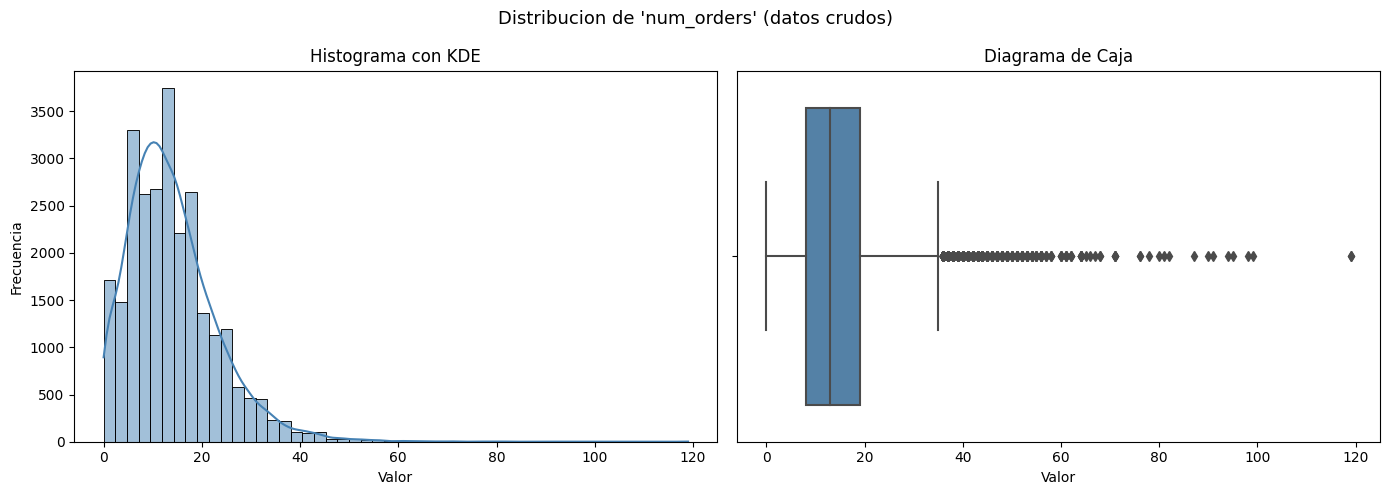

--- DATOS REMUESTREADOS A 1 HORA ---
Registros: 4416
                     num_orders
datetime                       
2018-03-01 00:00:00         124
2018-03-01 01:00:00          85
2018-03-01 02:00:00          71
2018-03-01 03:00:00          66
2018-03-01 04:00:00          43


In [2]:
df_raw = pd.read_csv('/datasets/taxi.csv', index_col=[0], parse_dates=[0])

explorador = TimeSeriesExplorer(df_raw, target_col='num_orders')
explorador.ejecutar_pipeline()

df = df_raw.copy()
df.sort_index(inplace=True)
df = df.resample('1H').sum()

print("--- DATOS REMUESTREADOS A 1 HORA ---")
print(f"Registros: {df.shape[0]}")
print(df.head())


## Analisis y Descomposicion de la Serie Temporal

La descomposicion aditiva separa la serie en tres componentes independientes:

| Componente | Descripcion |
|---|---|
| **Tendencia** | Direccion sostenida de los pedidos a lo largo del periodo (marzo — agosto) |
| **Estacionalidad** | Patron ciclico repetitivo; se usa `period=24` para capturar el ciclo diario (24 horas) |
| **Residuos** | Variacion aleatoria no explicada por los dos componentes anteriores |

El parametro `period=24` corresponde a la frecuencia del ciclo estacional esperado en datos horarios: un dia tiene 24 observaciones.

Para visualizar el patron estacional con claridad, se grafica un subconjunto de una semana (1 al 7 de marzo).


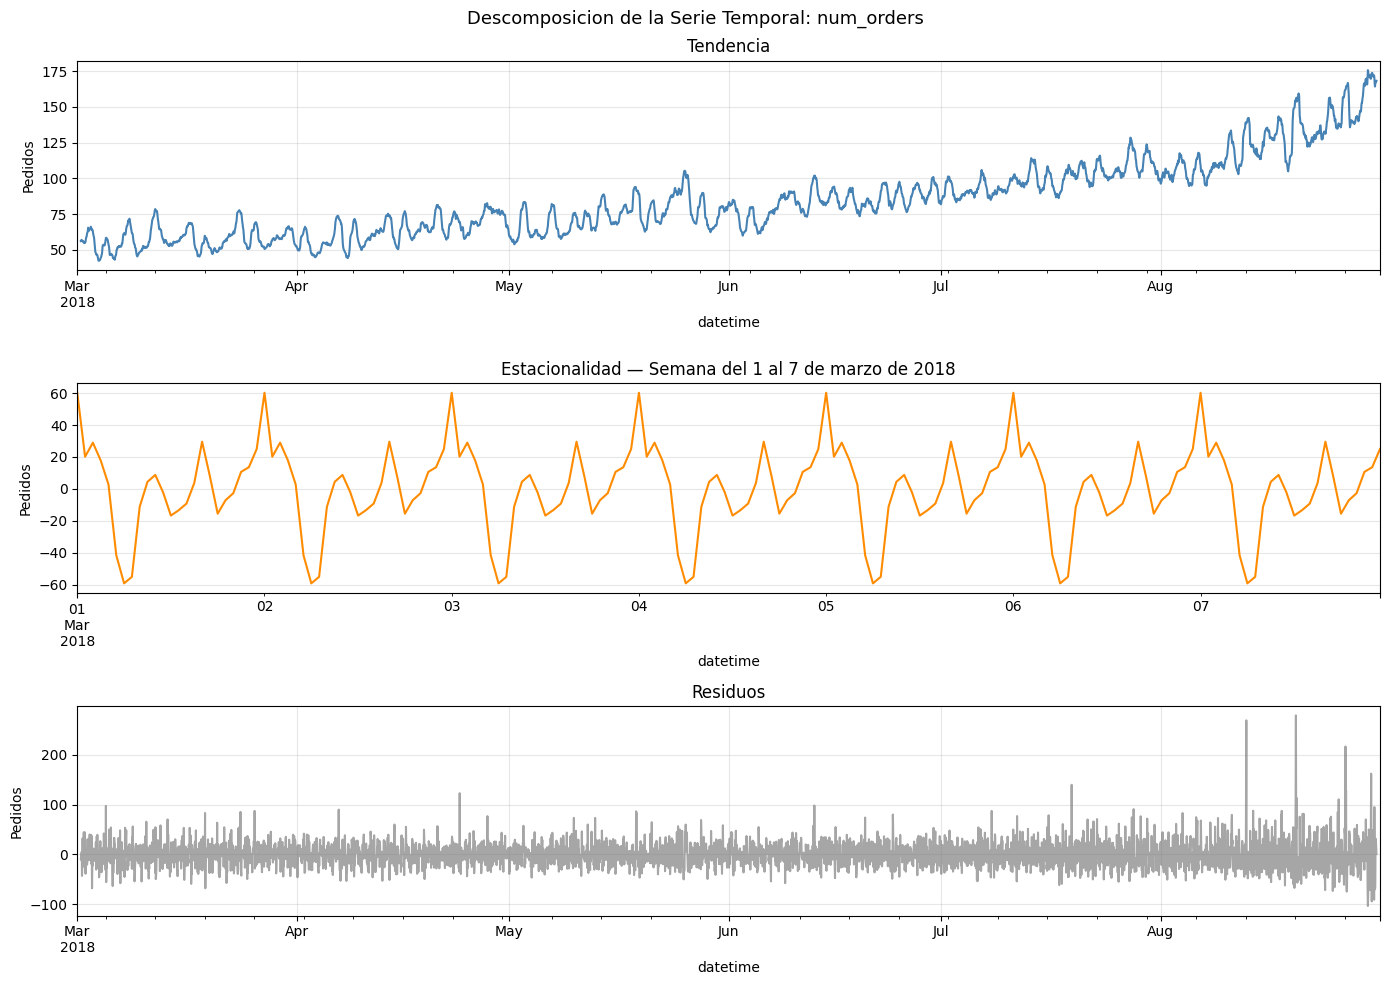

In [3]:
decomposed = seasonal_decompose(df['num_orders'], period=24)

fig, axes = plt.subplots(3, 1, figsize=(14, 10))
fig.suptitle('Descomposicion de la Serie Temporal: num_orders', fontsize=13)

decomposed.trend.plot(ax=axes[0], color='steelblue')
axes[0].set_title('Tendencia')
axes[0].set_ylabel('Pedidos')
axes[0].grid(True, alpha=0.3)

decomposed.seasonal['2018-03-01':'2018-03-07'].plot(ax=axes[1], color='darkorange')
axes[1].set_title('Estacionalidad — Semana del 1 al 7 de marzo de 2018')
axes[1].set_ylabel('Pedidos')
axes[1].grid(True, alpha=0.3)

decomposed.resid.plot(ax=axes[2], color='grey', alpha=0.7)
axes[2].set_title('Residuos')
axes[2].set_ylabel('Pedidos')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## Ingenieria de Caracteristicas

Los modelos de machine learning requieren caracteristicas numericas explicitas. Se define la funcion `make_features()` que genera tres categorias de variables a partir de la serie temporal:

| Categoria | Variables | Justificacion |
|---|---|---|
| **Calendario** | `month`, `day`, `dayofweek`, `hour` | Capturan la estacionalidad ciclica (hora del dia, dia de la semana, mes) |
| **Lags** | `lag_1` a `lag_24` | Aportan el valor historico de las ultimas 24 horas como contexto al modelo |
| **Media movil** | `rolling_mean` | Promedio de las 24 horas anteriores; resume la tendencia local reciente |

**Nota sobre data leakage:** Tanto los lags como la media movil aplican un desplazamiento (`shift`) de al menos 1 paso hacia adelante antes de calcularse. Esto asegura que en el momento de predecir la hora `t`, el modelo solo tenga acceso a informacion de horas anteriores a `t`, evitando fuga de informacion del futuro.

Tras generar las caracteristicas, se eliminan las filas con valores nulos (`dropna`) que surgen del desplazamiento inicial.


In [8]:
def make_features(data: pd.DataFrame, max_lag: int, rolling_mean_size: int) -> pd.DataFrame:
    """
    Genera caracteristicas temporales, de rezago y media movil.

    Parametros
    ----------
    data : pd.DataFrame
        DataFrame con DatetimeIndex y columna 'num_orders'.
    max_lag : int
        Numero de lags a crear (de lag_1 a lag_max_lag).
    rolling_mean_size : int
        Ventana en periodos para la media movil.

    Retorna
    -------
    pd.DataFrame con las nuevas columnas de caracteristicas.
    """
    df_feat = data.copy()

    df_feat['month']     = df_feat.index.month
    df_feat['day']       = df_feat.index.day
    df_feat['dayofweek'] = df_feat.index.dayofweek
    df_feat['hour']      = df_feat.index.hour

    for lag in range(1, max_lag + 1):
        df_feat[f'lag_{lag}'] = df_feat['num_orders'].shift(lag)

    df_feat['rolling_mean'] = (
        df_feat['num_orders'].shift(1).rolling(rolling_mean_size).mean()
    )

    return df_feat

df_features = make_features(df, max_lag=24, rolling_mean_size=24)
df_features.dropna(inplace=True)

print(f"Dimensiones tras ingenieria de caracteristicas: {df_features.shape}")
print(f"Columnas: {list(df_features.columns)}")
print(df_features.head())


Dimensiones tras ingenieria de caracteristicas: (4392, 30)
Columnas: ['num_orders', 'month', 'day', 'dayofweek', 'hour', 'lag_1', 'lag_2', 'lag_3', 'lag_4', 'lag_5', 'lag_6', 'lag_7', 'lag_8', 'lag_9', 'lag_10', 'lag_11', 'lag_12', 'lag_13', 'lag_14', 'lag_15', 'lag_16', 'lag_17', 'lag_18', 'lag_19', 'lag_20', 'lag_21', 'lag_22', 'lag_23', 'lag_24', 'rolling_mean']
                     num_orders  month  day  dayofweek  hour  lag_1  lag_2  \
datetime                                                                     
2018-03-02 00:00:00          90      3    2          4     0   58.0  113.0   
2018-03-02 01:00:00         120      3    2          4     1   90.0   58.0   
2018-03-02 02:00:00          75      3    2          4     2  120.0   90.0   
2018-03-02 03:00:00          64      3    2          4     3   75.0  120.0   
2018-03-02 04:00:00          20      3    2          4     4   64.0   75.0   

                     lag_3  lag_4  lag_5  ...  lag_16  lag_17  lag_18  lag_19  \
date

## Division Entrenamiento / Prueba

El conjunto de prueba corresponde al **10% final** del dataset. El parametro `shuffle=False` es obligatorio en series temporales: si se permutaran los datos, se filtraria informacion futura hacia el conjunto de entrenamiento, invalidando la evaluacion.

| Conjunto | Proporcion | Uso |
|---|---|---|
| Entrenamiento | 90% | Ajuste de parametros y validacion cruzada |
| Prueba | 10% | Evaluacion final del modelo seleccionado |


In [5]:
X = df_features.drop('num_orders', axis=1)
y = df_features['num_orders']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.1, shuffle=False
)

print(f"Registros de entrenamiento : {X_train.shape[0]}")
print(f"Registros de prueba        : {X_test.shape[0]}")


Registros de entrenamiento : 3952
Registros de prueba        : 440


## Entrenamiento y Seleccion de Modelos

Se evaluan cuatro modelos con diferentes capacidades de representacion:

| Modelo | Tipo | Proposito en el experimento |
|---|---|---|
| Regresion Lineal | Lineal | Linea base (baseline) |
| Arbol de Decision | No lineal | Modelo simple, interpretable |
| Random Forest | Ensamble de arboles | Reduccion de varianza por promediado |
| LightGBM | Gradient boosting | Alta precision; optimizado para velocidad |

**Validacion cruzada temporal (`TimeSeriesSplit`, 5 splits):**
En series temporales la validacion cruzada convencional mezcla pasado y futuro. `TimeSeriesSplit` garantiza que cada fold de validacion sea siempre posterior al fold de entrenamiento, respetando el orden cronologico.

**Busqueda de hiperparametros (`GridSearchCV`):**
Para cada modelo se define una cuadricula (`param_grid`) de valores candidatos. `GridSearchCV` entrena el modelo con cada combinacion posible y selecciona la que minimiza la RECM en la validacion cruzada.


In [6]:
tscv  = TimeSeriesSplit(n_splits=5)
tuner = ModelTuner(X_train, y_train, cv=tscv)

tuner.evaluar_modelo(
    "Regresion Lineal",
    LinearRegression()
)

tuner.evaluar_modelo(
    "Arbol de Decision",
    DecisionTreeRegressor(random_state=12345),
    param_grid={'max_depth': [5, 10, 15, None]}
)

tuner.evaluar_modelo(
    "Random Forest",
    RandomForestRegressor(random_state=12345),
    param_grid={
        'n_estimators': [50, 100],
        'max_depth':    [10, 15, None]
    }
)

tuner.evaluar_modelo(
    "LightGBM",
    lgb.LGBMRegressor(random_state=12345, verbose=-1),
    param_grid={
        'n_estimators':  [100, 200],
        'learning_rate': [0.05, 0.1],
        'max_depth':     [5, 10]
    }
)

mejor_modelo = tuner.mostrar_resumen()


[Regresion Lineal]  RECM CV: 26.9450 | T.Entrenamiento: 0.004s | T.Prediccion: 0.0031s
[Arbol de Decision]  RECM CV: 30.4741 | T.Entrenamiento: 0.472s | T.Prediccion: 0.0018s
[Random Forest]  RECM CV: 25.2409 | T.Entrenamiento: 26.549s | T.Prediccion: 0.0560s
[LightGBM]  RECM CV: 24.7620 | T.Entrenamiento: 2.834s | T.Prediccion: 0.0053s

--- LEADERBOARD ---
           Modelo  RECM_CV  T_Train_s  T_Pred_s                                                  Parametros
         LightGBM  24.7620      2.834    0.0053 {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 100}
    Random Forest  25.2409     26.549    0.0560                    {'max_depth': None, 'n_estimators': 100}
 Regresion Lineal  26.9450      0.004    0.0031                                                          {}
Arbol de Decision  30.4741      0.472    0.0018                                            {'max_depth': 5}

Modelo seleccionado: LightGBM | RECM CV: 24.7620


## Evaluacion Final en el Conjunto de Prueba

El modelo seleccionado por el leaderboard se aplica sobre `X_test`, que no fue utilizado en ninguna etapa anterior del entrenamiento ni de la validacion cruzada.

Se calcula la RECM como medida de error principal y se verifica que sea inferior al umbral de **48** pedidos por hora establecido como criterio de exito del proyecto.

Adicionalmente, se grafica la comparacion entre los valores reales y las predicciones para las primeras 100 horas del conjunto de prueba, permitiendo evaluar visualmente el comportamiento del modelo en el tiempo.


RECM en conjunto de prueba : 41.22
Umbral requerido            : 48.00
Resultado                   : APROBADO


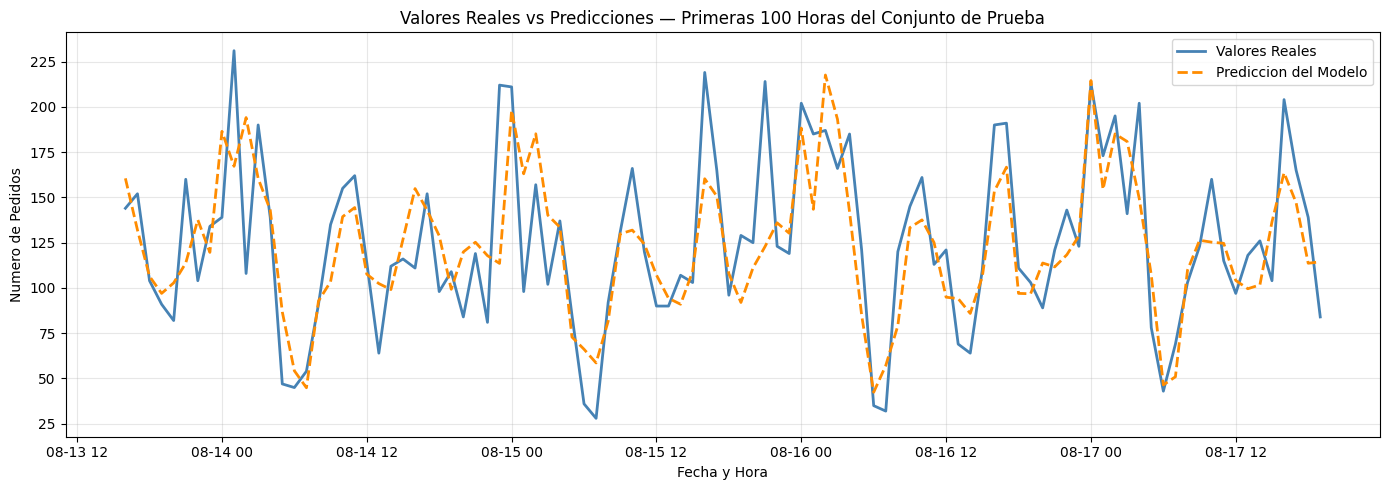

In [7]:
pred_test = mejor_modelo.predict(X_test)
rmse_test = np.sqrt(mean_squared_error(y_test, pred_test))

print(f"RECM en conjunto de prueba : {rmse_test:.2f}")
print(f"Umbral requerido            : 48.00")
print(f"Resultado                   : {'APROBADO' if rmse_test < 48 else 'NO APROBADO'}")

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(
    y_test.index[:100], y_test.values[:100],
    label='Valores Reales', color='steelblue', linewidth=2
)
ax.plot(
    y_test.index[:100], pred_test[:100],
    label='Prediccion del Modelo', color='darkorange',
    linestyle='--', linewidth=2
)
ax.set_title('Valores Reales vs Predicciones — Primeras 100 Horas del Conjunto de Prueba')
ax.set_xlabel('Fecha y Hora')
ax.set_ylabel('Numero de Pedidos')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# Conclusion General

1. **Carga y preparacion:** Los datos originales comprenden 26,496 registros a intervalos de 10 minutos, sin valores nulos y con indice cronologico valido. Tras el remuestreo horario por suma acumulada, el dataset queda reducido a 4,416 registros.

2. **Analisis de la serie:** La tendencia de 7 dias revela un crecimiento sostenido en el volumen de pedidos entre marzo y agosto de 2018. El patron estacional muestra un ciclo diario consistente con maximos nocturnos y minimos en la madrugada.

3. **Ingenieria de caracteristicas:** Se generaron 29 variables de entrada: 4 de calendario (mes, dia, dia de la semana, hora), 24 lags horarios y 1 media movil de 24 horas. El desplazamiento previo al calculo de cada variable elimina la posibilidad de fuga de informacion del futuro.

4. **Seleccion de modelo:** Los cuatro modelos evaluados con `TimeSeriesSplit` (5 folds) y `GridSearchCV` produjeron los siguientes resultados de RECM en validacion cruzada:

| Modelo | RECM CV |
|---|---|
|  LightGBM  | 24.76 |
| Random Forest | 25.24 |
| Regresion Lineal | 26.95 |
| Arbol de Decision | 30.47 |

5. **Resultado final:** El modelo LightGBM, seleccionado automaticamente por `ModelTuner`, obtuvo una **RECM de 41.22** en el conjunto de prueba, por debajo del umbral de 48, cumpliendo el criterio de exito del proyecto.


- [x]  	
Jupyter Notebook está abierto.
- [ ]  El código no tiene errores
- [ ]  Las celdas con el código han sido colocadas en el orden de ejecución.
- [ ]  	
Los datos han sido descargados y preparados.
- [ ]  Se ha realizado el paso 2: los datos han sido analizados
- [ ]  Se entrenó el modelo y se seleccionaron los hiperparámetros
- [ ]  Se han evaluado los modelos. Se expuso una conclusión
- [ ] La *RECM* para el conjunto de prueba no es más de 48
